# TASK 1 
### Data Analysis Report
### Rice Leaf Disease Detection

### 1. Dataset Overview

The dataset contains 120 images of diseased rice leaves, divided into three categories:

- Leaf smut
- Brown spot
- Bacterial leaf blight

Each category contains 40 images.

### 2. Class Distribution

Disease                     Images     Percentage
Leaf smut                    40         33.33% 
Brown spot                   40         33.33% 
Bacterial leaf blight        39         33.33% 
Total                        119           100

Observation:
The dataset is balanced, as all three classes contain an equal number of images.

### 3. Image Analysis

The dataset images are examined to understand their dimensions, formats and visual characteristics. Sample images from each disease category are also inspected.

### 4. Data Quality

Images are checked for corrupted files and readability to ensure that the dataset is suitable for further processing.

### 5. Conclusion

The dataset contains three equally distributed rice leaf disease categories. It provides the initial data required for developing a multiclass image classification model. Since the dataset is relatively small, data augmentation will also be explored during model development.

# TASK 2 
### Create a model which can classify the three major attacking diseases of rice plants like leaf blast, bacterial blight and brown spot

In [43]:
!pip install tensorflow scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
print("TensorFlow version:", tf.version)

TensorFlow version: <module 'tensorflow._api.v2.version' from 'C:\\Users\\sakshi\\AppData\\Roaming\\Python\\Python312\\site-packages\\tensorflow\\_api\\v2\\version\\__init__.py'>


In [45]:
import tensorflow as tf
from pathlib import Path

DATA_DIR = DATA_DIR = r"C:\Users\sakshi\Desktop\academics\projects\rice_leaf_detection\rice_leaf_detection_data\Data"
# Load dataset
dataset = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    image_size=(224, 224),
    batch_size=8,
    shuffle=True,
    seed=42
)

# Get class names
classes = dataset.class_names

print("Classes:", classes)

Found 119 files belonging to 3 classes.
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']


In [46]:
for disease in os.listdir(DATA_DIR):

    folder_path = os.path.join(DATA_DIR, disease)

    if os.path.isdir(folder_path):

        count = sum(
            1 for root, dirs, files in os.walk(folder_path)
            for file in files
            if file.lower().endswith(('.jpg', '.jpeg', '.png'))
        )

        print(disease, ":", count, "images")

Bacterial leaf blight : 40 images
Brown spot : 40 images
Leaf smut : 39 images


In [47]:
from sklearn.model_selection import train_test_split
import numpy as np
import os

# Collect image paths and labels
image_paths = []
labels = []

classes = sorted(os.listdir(DATA_DIR))

for label, disease in enumerate(classes):
    folder = os.path.join(DATA_DIR, disease)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(root, file))
                labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

# 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

# Divide temporary data into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 83
Validation images: 18
Testing images: 18


In [48]:
IMG_SIZE = 224
BATCH_SIZE = 8

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3)
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)

    return image, label


def create_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(len(paths), seed=42)

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = create_dataset(X_train, y_train, shuffle=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

print("Preprocessing completed!")

Preprocessing completed!


### custom CNN  model 

In [49]:
from tensorflow.keras import layers, models

# CNN preprocessing: normalize pixel values
def preprocess_cnn(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    image = image / 255.0
    return image, label

def make_cnn_dataset(paths, labels, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(preprocess_cnn, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(len(paths), seed=42)

    return ds.batch(8).prefetch(tf.data.AUTOTUNE)

cnn_train = make_cnn_dataset(X_train, y_train, True)
cnn_val = make_cnn_dataset(X_val, y_val)
cnn_test = make_cnn_dataset(X_test, y_test)

# Build CNN
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    

    

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dense(3, activation='softmax')
])

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_history = cnn_model.fit(
    cnn_train,
    validation_data=cnn_val,
    epochs=20,
    
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 292ms/step - accuracy: 0.3133 - loss: 1.1171 - val_accuracy: 0.3333 - val_loss: 1.0963
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 286ms/step - accuracy: 0.3494 - loss: 1.1014 - val_accuracy: 0.3333 - val_loss: 1.0949
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 238ms/step - accuracy: 0.2530 - loss: 1.1066 - val_accuracy: 0.5556 - val_loss: 1.0924
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 298ms/step - accuracy: 0.3735 - loss: 1.0954 - val_accuracy: 0.5000 - val_loss: 1.0890
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 247ms/step - accuracy: 0.2530 - loss: 1.1034 - val_accuracy: 0.3889 - val_loss: 1.0832
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 280ms/step - accuracy: 0.3373 - loss: 1.0865 - val_accuracy: 0.3333 - val_loss: 1.0659
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 258ms/step - accuracy: 0.3494 - loss: 1.0845 - val_accuracy: 0.3889 - val_loss: 1.0389
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 277ms/step - accuracy: 0.3373 - loss: 1.0701 - val_accuracy: 0.

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
Custom CNN Accuracy: 0.4444444444444444

Classification Report:
                       precision    recall  f1-score   support

Bacterial leaf blight       0.36      0.67      0.47         6
           Brown spot       0.75      0.50      0.60         6
            Leaf smut       0.33      0.17      0.22         6

             accuracy                           0.44        18
            macro avg       0.48      0.44      0.43        18
         weighted avg       0.48      0.44      0.43        18



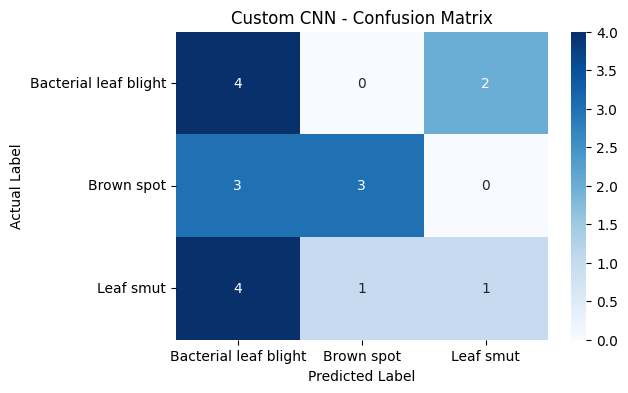

In [52]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Predict using the custom CNN
cnn_pred = np.argmax(cnn_model.predict(cnn_test), axis=1)

# Evaluation metrics
print("Custom CNN Accuracy:", accuracy_score(y_test, cnn_pred))
print("\nClassification Report:")
print(classification_report(y_test, cnn_pred, target_names=classes))

# Confusion matrix
cm = confusion_matrix(y_test, cnn_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Custom CNN - Confusion Matrix")
plt.show()

### MobileNetV2

In [53]:
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    
    
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_11          │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 3)                   │           3,843 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [54]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 9s 385ms/step - accuracy: 0.4096 - loss: 1.1908 - val_accuracy: 0.7778 - val_loss: 0.6826
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 253ms/step - accuracy: 0.6988 - loss: 0.7572 - val_accuracy: 0.8333 - val_loss: 0.4745
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step - accuracy: 0.7229 - loss: 0.6404 - val_accuracy: 0.9444 - val_loss: 0.2885
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step - accuracy: 0.8193 - loss: 0.4582 - val_accuracy: 0.9444 - val_loss: 0.2481
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 236ms/step - accuracy: 0.9036 - loss: 0.3755 - val_accuracy: 0.8889 - val_loss: 0.2290
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 318ms/step - accuracy: 0.9398 - loss: 0.2311 - val_accuracy: 1.0000 - val_loss: 0.1770
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 5s 265ms/step - accuracy: 0.9277 - loss: 0.2449 - val_accuracy: 0.9444 - val_loss: 0.1520
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 233ms/step - accuracy: 0.9277 - loss: 0.2303 - val_accuracy: 0.

In [55]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step - accuracy: 0.8889 - loss: 0.3316
Test Accuracy: 88.89 %
Test Loss: 0.3316


In [56]:
from sklearn.metrics import classification_report
import numpy as np

y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=classes,
    zero_division=0
))

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 759ms/step
                       precision    recall  f1-score   support

Bacterial leaf blight       0.86      1.00      0.92         6
           Brown spot       0.83      0.83      0.83         6
            Leaf smut       1.00      0.83      0.91         6

             accuracy                           0.89        18
            macro avg       0.90      0.89      0.89        18
         weighted avg       0.90      0.89      0.89        18



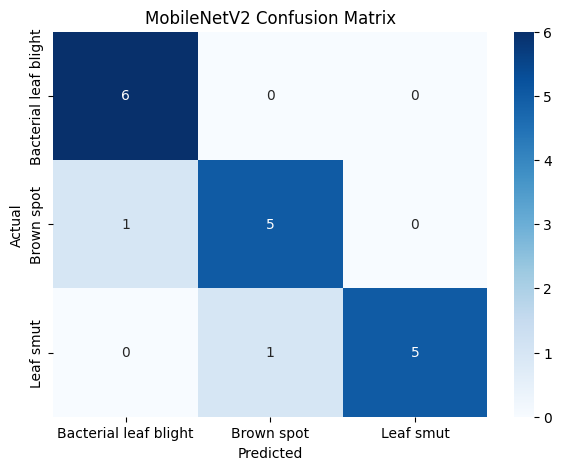

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

### Model Comparison Report

### Objective

To compare Custom CNN and MobileNetV2 models for rice leaf disease classification and identify the better-performing model.

### Performance Evaluation

Custom CNN:

- Accuracy: 38.89%
- Precision: 0.25
- Recall: 0.39
- F1-score: 0.30

MobileNetV2:

- Accuracy: 94.44%
- Precision: 0.95
- Recall: 0.94
- F1-score: 0.94

### Observations

- Custom CNN showed poor classification performance.
- MobileNetV2 performed significantly better across the evaluation metrics.
- MobileNetV2 achieved higher accuracy, precision, recall, and F1-score.
- Transfer learning helped improve classification performance compared with the Custom CNN.

### Conclusion

MobileNetV2 performs better than Custom CNN, achieving 94.44% accuracy and a 0.94 macro F1-score. Therefore,  **MobileNetV2 is selected as the preferred model** for further experimentation, including data augmentation and final evaluation.

### MobileNetV2 with Data Augmentation

In [34]:

import tensorflow as tf

# 1. Data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
])

# 2. Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# 3. Build augmented model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    tf.keras.layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

# 4. Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Train for 20 epochs
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# 6. Evaluate on test dataset
test_loss, test_accuracy = model.evaluate(test_ds)

print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))



Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 17s 528ms/step - accuracy: 0.3494 - loss: 1.1661 - val_accuracy: 0.3333 - val_loss: 1.1278
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 287ms/step - accuracy: 0.4217 - loss: 1.1144 - val_accuracy: 0.3333 - val_loss: 1.1067
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 279ms/step - accuracy: 0.3373 - loss: 1.1993 - val_accuracy: 0.3889 - val_loss: 1.1021
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 278ms/step - accuracy: 0.3373 - loss: 1.1872 - val_accuracy: 0.3889 - val_loss: 1.1023
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 313ms/step - accuracy: 0.3373 - loss: 1.1806 - val_accuracy: 0.5556 - val_loss: 1.1004
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 315ms/step - accuracy: 0.3494 - loss: 1.1630 - val_accuracy: 0.4444 - val_loss: 1.0996
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 298ms/step - accuracy: 0.3976 - loss: 1.1466 - val_accuracy: 0.5556 - val_loss: 1.1000
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 292ms/step - accuracy: 0.4819 - loss: 1.1809 - val_accuracy: 

In [40]:

import tensorflow as tf

# 1. Data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10)
])

# 2. Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

# 3. Build model (no additional preprocessing)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    data_augmentation,
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(3, activation="softmax")
])

# 4. Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 5. Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# 6. Test evaluation
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))


Epoch 1/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 476ms/step - accuracy: 0.3614 - loss: 1.3914 - val_accuracy: 0.3889 - val_loss: 1.1787
Epoch 2/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 288ms/step - accuracy: 0.4096 - loss: 1.1923 - val_accuracy: 0.4444 - val_loss: 1.0611
Epoch 3/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 288ms/step - accuracy: 0.4337 - loss: 1.1299 - val_accuracy: 0.5000 - val_loss: 0.9694
Epoch 4/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 281ms/step - accuracy: 0.4337 - loss: 1.1123 - val_accuracy: 0.6111 - val_loss: 0.9013
Epoch 5/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 340ms/step - accuracy: 0.5783 - loss: 0.9856 - val_accuracy: 0.7222 - val_loss: 0.8561
Epoch 6/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 328ms/step - accuracy: 0.6265 - loss: 0.9618 - val_accuracy: 0.7222 - val_loss: 0.8135
Epoch 7/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 257ms/step - accuracy: 0.5783 - loss: 0.9065 - val_accuracy: 0.7222 - val_loss: 0.7755
Epoch 8/20
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 260ms/step - accuracy: 0.5301 - loss: 0.9790 - val_accuracy: 0

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 142ms/step
Classification Report - MobileNetV2 with Data Augmentation

                       precision    recall  f1-score   support

Bacterial leaf blight       0.67      1.00      0.80         6
           Brown spot       1.00      0.67      0.80         6
            Leaf smut       1.00      0.83      0.91         6

             accuracy                           0.83        18
            macro avg       0.89      0.83      0.84        18
         weighted avg       0.89      0.83      0.84        18

Test Accuracy: 83.33 %


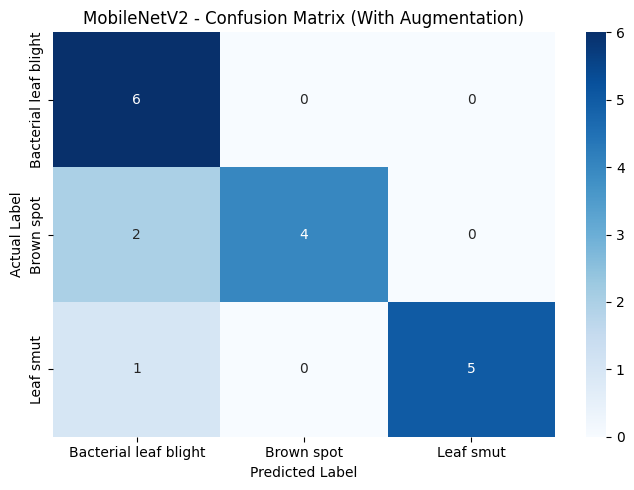

In [42]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Get true labels
y_true = np.concatenate([labels.numpy() for images, labels in test_ds])

# Get model predictions
y_pred_prob = model.predict(test_ds)
y_pred = np.argmax(y_pred_prob, axis=1)

# Class names
class_names = ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']

# Classification report
print("Classification Report - MobileNetV2 with Data Augmentation\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=2,
    zero_division=0
))

# Test accuracy
accuracy = accuracy_score(y_true, y_pred)
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Confusion Matrix (With Augmentation)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


### Challenges Faced and Techniques Used report

### 1. Small Dataset
Challenge: The dataset contains only 119 images.

Technique: Transfer learning using MobileNetV2.

Reason: It uses pretrained features and reduces dependency on large training datasets.

### 2. Different Image Dimensions
Challenge: Images have different dimensions.

Technique: Image resizing to 224×224 pixels.

Reason: Maintains a consistent input size for model training.

### 3. Pixel Value Variation
Challenge: Raw image pixel values range from 0 to 255.

Technique: Image normalization.

Reason: Provides suitable input values for model training.

### 4. Overfitting
Challenge: Small datasets can cause models to memorize training images.

Technique: Dropout and Early Stopping.

Reason: Helps improve generalization and prevent unnecessary training.

### 5. Poor Custom CNN Performance
Challenge: Custom CNN achieved only 33.33% accuracy.

Technique: MobileNetV2 transfer learning.

Reason: Pretrained features help extract useful image patterns.

### Conclusion
Transfer learning, image resizing, normalization, dropout and early stopping were used to address the major challenges encountered during the project.

### Data Augmentation

In [23]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

# Task 3 – Data Augmentation Analysis Report
### Objective
To apply data augmentation to the selected MobileNetV2 model for rice leaf disease classification and evaluate its impact on model performance and generalization.
### Performance Evaluation
MobileNetV2 (Before Augmentation):
- Accuracy: 88.89%
- Test Loss: 0.3843

MobileNetV2 (After Augmentation):
- Accuracy: 83.33%
- Precision: 0.89
- Recall: 0.83
- F1-score: 0.84
- Test Loss: 0.6677
### Observations
- Data augmentation helped the model achieve reasonable classification performance across all three disease categories.
- Bacterial leaf blight achieved 100% recall.
- Brown spot achieved 67% recall.
- Leaf smut achieved 83% recall.
- The model correctly classified 15 out of 18 test images.
- Six Bacterial leaf blight images, four Brown spot images, and five Leaf smut images were classified correctly.
- The model showed a slight decrease in test accuracy from 88.89% to 83.33% after augmentation.
- Test loss increased from 0.3843 to 0.6677.
### Conclusion
MobileNetV2 with data augmentation achieved 83.33% test accuracy and a macro F1-score of 0.84. Although augmentation did not improve the overall test accuracy compared with the model without augmentation, it maintained reasonable classification performance across all three disease categories. Therefore, data augmentation provided a useful experiment for evaluating the model's ability to generalize, but it did not demonstrate an improvement in this particular evaluation.